# 02 Analisis Fitur & Lag Time-Series (Feature Analysis)


---
### 1. Setup Environment


In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path(r"c:\Project\napasloka\napasloka")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


---
### 2. Pemilihan Stasiun & Pemuatan Data


In [2]:
import numpy as np
import pandas as pd

from src.features.lag_features import create_lag_features
from src.features.scenarios import resolve_scenario
from src.data.clean_data import chronological_train_test_split
from src.utils.config import load_yaml_config

STATION_ID = "pantai-makmur"
POLLUTANT = "co2"

df_raw = pd.read_csv(ROOT_DIR / "data" / "processed" / f"jabodetabek_{POLLUTANT}_dataset.csv")
df_raw["datetime"] = pd.to_datetime(df_raw["datetime"], utc=True).dt.tz_convert("Asia/Jakarta")

locations_cfg = load_yaml_config("locations.yaml").get("locations", [])
loc_info = next((l for l in locations_cfg if l["id"] == STATION_ID), None)
coord_id = f"{loc_info['latitude']}_{loc_info['longitude']}" if loc_info else STATION_ID

df_station = df_raw[(df_raw["location"] == coord_id) | (df_raw["location"] == STATION_ID)].sort_values("datetime").reset_index(drop=True)
print(f"Stasiun Terpilih : {loc_info['name'] if loc_info else STATION_ID} ({len(df_station)} baris)")
print(f"Rentang Waktu    : {df_station['datetime'].min()} s.d. {df_station['datetime'].max()}")


Stasiun Terpilih : Pantai Makmur (15545 baris)
Rentang Waktu    : 2024-10-26 07:00:00+07:00 s.d. 2026-08-04 23:00:00+07:00


---
### 3. Analisis Autokorelasi & Parsial Autokorelasi Fitur Lag (ACF & PACF)

Analisis **Autocorrelation Function (ACF)** dan **Partial Autocorrelation Function (PACF)** dilakukan untuk menentukan jendela lag temporal optimal ($t-1, t-2, \dots$) pada deret waktu polutan **CO** dan **CO₂**:
- **ACF**: Mengukur korelasi linear total antara nilai saat ini ($y_t$) dengan nilai masa lalu ($y_{t-k}$), termasuk efek perantara (*indirect effects*). Kurva ACF yang meluruh perlahan (*slow decay*) mengindikasikan persistensi/kelembaman temporal yang kuat.
- **PACF**: Mengukur korelasi langsung (*direct correlation*) murni antara $y_t$ dan $y_{t-k}$ setelah mengontrol seluruh lag perantara ($y_{t-1}, \dots, y_{t-k+1}$). Pola *cut-off* pada PACF memberikan justifikasi empiris terhadap jumlah lag maksimum yang diperlukan sebelum mengalami multikolinearitas dan penurunan signifikansi.

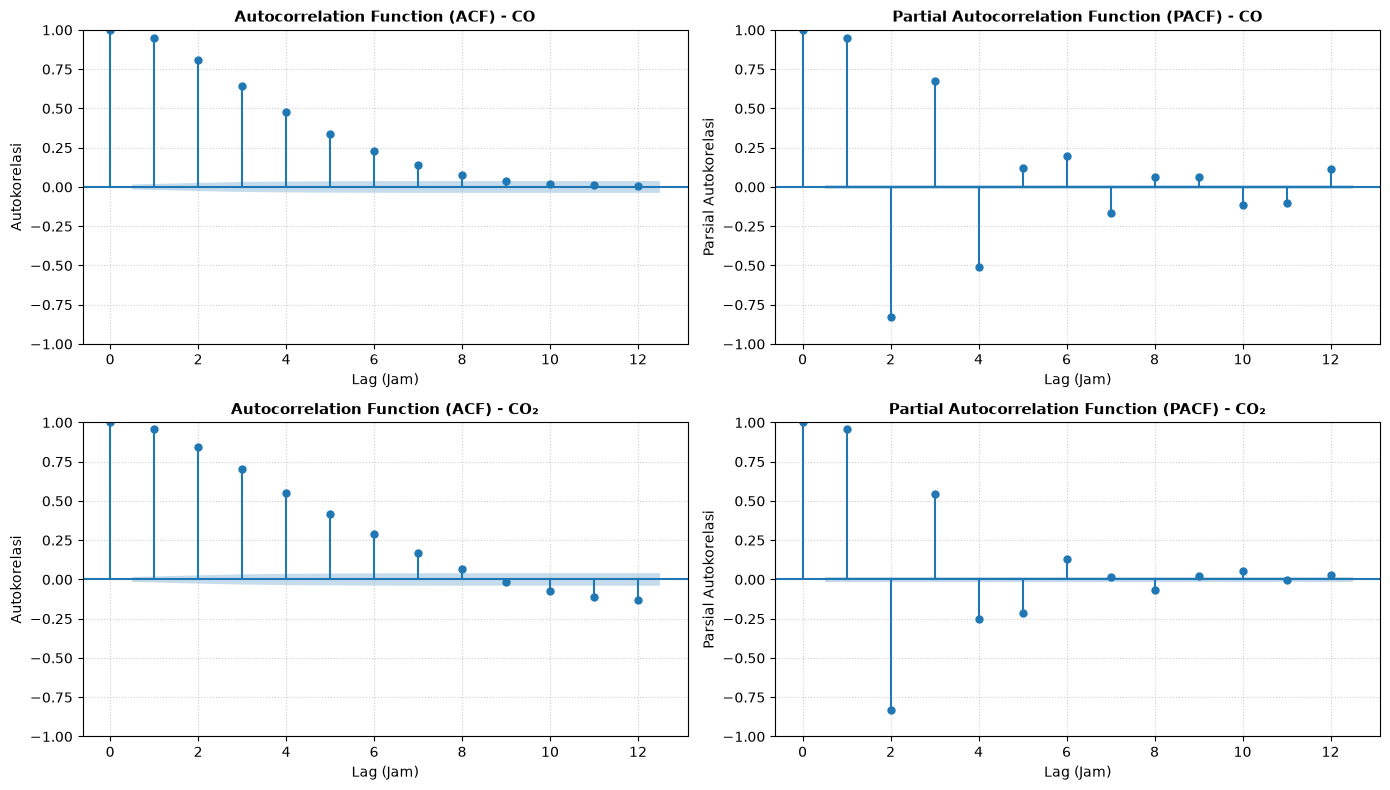

In [3]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Memuat data CO dan CO₂ untuk stasiun terpilih
df_raw_co = pd.read_csv(ROOT_DIR / "data" / "processed" / "jabodetabek_co_dataset.csv")
df_raw_co["datetime"] = pd.to_datetime(df_raw_co["datetime"], utc=True).dt.tz_convert("Asia/Jakarta")
df_station_co = df_raw_co[(df_raw_co["location"] == coord_id) | (df_raw_co["location"] == STATION_ID)].sort_values("datetime").reset_index(drop=True)

df_raw_co2 = pd.read_csv(ROOT_DIR / "data" / "processed" / "jabodetabek_co2_dataset.csv")
df_raw_co2["datetime"] = pd.to_datetime(df_raw_co2["datetime"], utc=True).dt.tz_convert("Asia/Jakarta")
df_station_co2 = df_raw_co2[(df_raw_co2["location"] == coord_id) | (df_raw_co2["location"] == STATION_ID)].sort_values("datetime").reset_index(drop=True)

# Visualisasi 4 Subplot: ACF & PACF untuk CO dan CO₂
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 1. CO - ACF
plot_acf(df_station_co["carbon_monoxide"].dropna(), lags=12, alpha=0.05, ax=axes[0, 0])
axes[0, 0].set_title("Autocorrelation Function (ACF) - CO", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Lag (Jam)")
axes[0, 0].set_ylabel("Autokorelasi")
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

# 2. CO - PACF
plot_pacf(df_station_co["carbon_monoxide"].dropna(), lags=12, alpha=0.05, method="ywm", ax=axes[0, 1])
axes[0, 1].set_title("Partial Autocorrelation Function (PACF) - CO", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Lag (Jam)")
axes[0, 1].set_ylabel("Parsial Autokorelasi")
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

# 3. CO₂ - ACF
plot_acf(df_station_co2["carbon_dioxide"].dropna(), lags=12, alpha=0.05, ax=axes[1, 0])
axes[1, 0].set_title("Autocorrelation Function (ACF) - CO₂", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Lag (Jam)")
axes[1, 0].set_ylabel("Autokorelasi")
axes[1, 0].grid(True, linestyle=":", alpha=0.6)

# 4. CO₂ - PACF
plot_pacf(df_station_co2["carbon_dioxide"].dropna(), lags=12, alpha=0.05, method="ywm", ax=axes[1, 1])
axes[1, 1].set_title("Partial Autocorrelation Function (PACF) - CO₂", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Lag (Jam)")
axes[1, 1].set_ylabel("Parsial Autokorelasi")
axes[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


> **Temuan & Justifikasi Ilmiah Pemilihan Lag ($t-1, t-2, t-3$):**
>
> 1. **Dinamika Autoregresif Signifikan**: Baik pada CO maupun CO₂, nilai PACF menunjukkan korelasi langsung yang dominan dan melampaui batas signifikansi (area biru $\alpha = 0.05$) pada **lag 1, lag 2, dan lag 3**.
> 2. **Pola Cut-off**: Setelah lag 3, korelasi parsial mengalami penurunan tajam (*cut-off*) dan berfluktuasi di sekitar ambang batas selang kepercayaan 95%.
> 3. **Pencegahan Multikolinearitas**: Membatasi lag hingga 3 jam ke belakang ($t-1, t-2, t-3$) menangkap sebagian besar variansi ketergantungan temporal jangka pendek tanpa menimbulkan redundansi informasi (*multicollinearity*) atau pembengkakan dimensi (*curse of dimensionality*).

---
### 4. Pembentukan Fitur Lag: Skenario 1 vs Skenario 2


In [8]:
# Skenario 1: Hanya lag polutan (t-1, t-2, t-3)
df_s1 = create_lag_features(df_station, pollutant=POLLUTANT, scenario="scenario_1", drop_incomplete_rows=True)
# Skenario 2: Lag polutan + Lag meteorologi (t-1, t-2, t-3)
df_s2 = create_lag_features(df_station, pollutant=POLLUTANT, scenario="scenario_2", drop_incomplete_rows=True)

s1_def = resolve_scenario(POLLUTANT, "scenario_1")
s2_def = resolve_scenario(POLLUTANT, "scenario_2")

print(f"Skenario 1 Fitur ({len(s1_def.feature_names)} kolom): {list(s1_def.feature_names)}")
print(f"Skenario 2 Fitur ({len(s2_def.feature_names)} kolom): {list(s2_def.feature_names)}")
print(f"Baris setelah eliminasi NaN awal: {len(df_s2)} baris (Observasi awal dimulai: {df_s2['datetime'].min()})")


Skenario 1 Fitur (3 kolom): ['carbon_dioxide_lag_3h', 'carbon_dioxide_lag_2h', 'carbon_dioxide_lag_1h']
Skenario 2 Fitur (15 kolom): ['carbon_dioxide_lag_3h', 'carbon_dioxide_lag_2h', 'carbon_dioxide_lag_1h', 'temperature_2m_lag_3h', 'temperature_2m_lag_2h', 'temperature_2m_lag_1h', 'relative_humidity_2m_lag_3h', 'relative_humidity_2m_lag_2h', 'relative_humidity_2m_lag_1h', 'rain_lag_3h', 'rain_lag_2h', 'rain_lag_1h', 'wind_speed_100m_lag_3h', 'wind_speed_100m_lag_2h', 'wind_speed_100m_lag_1h']
Baris setelah eliminasi NaN awal: 15542 baris (Observasi awal dimulai: 2024-10-26 10:00:00+07:00)


---
### 5. Pembagian Kronologis 80% Train : 20% Test


RINCIAN PEMBAGIAN DATA DERET WAKTU (80:20)
Data Latih (80%): 12,433 baris | 2024-10-26 10:00:00+07:00 s.d. 2026-03-28 10:00:00+07:00
Data Uji   (20%): 3,109 baris | 2026-03-28 11:00:00+07:00 s.d. 2026-08-04 23:00:00+07:00


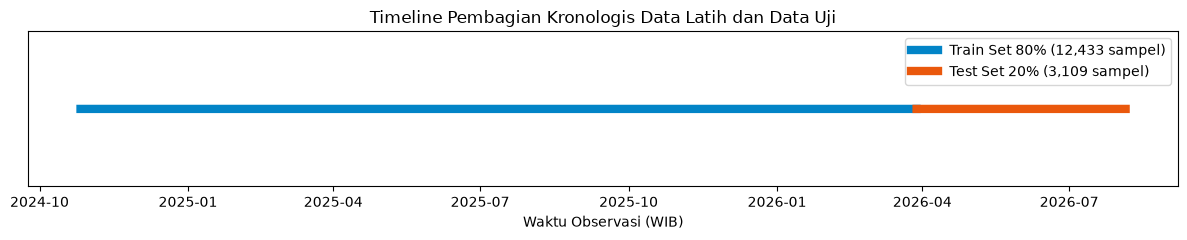

In [10]:
train_df, test_df = chronological_train_test_split(df_s2, test_fraction=0.2)

print("RINCIAN PEMBAGIAN DATA DERET WAKTU (80:20)")
print(f"Data Latih (80%): {len(train_df):,} baris | {train_df['datetime'].min()} s.d. {train_df['datetime'].max()}")
print(f"Data Uji   (20%): {len(test_df):,} baris | {test_df['datetime'].min()} s.d. {test_df['datetime'].max()}")

# Visualisasi Timeline Pembagian Data
plt.figure(figsize=(12, 2.5))
plt.plot(train_df["datetime"], np.ones(len(train_df)), color="#0284c7", linewidth=6, label=f"Train Set 80% ({len(train_df):,} sampel)")
plt.plot(test_df["datetime"], np.ones(len(test_df)), color="#ea580c", linewidth=6, label=f"Test Set 20% ({len(test_df):,} sampel)")
plt.title("Timeline Pembagian Kronologis Data Latih dan Data Uji", fontsize=12)
plt.yticks([])
plt.xlabel("Waktu Observasi (WIB)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()
